# Face Identification Using PCA and k-Nearest Neighbours

This notebook develops a closed-set face-identification system for five known identities. Face images are represented with PCA-based Eigenfaces and classified using k-Nearest Neighbours (k-NN).

The workflow is developed incrementally so that data preparation, model selection, final testing, and error analysis remain clearly separated.

## 1. Dataset exploration

The project uses the **Labeled Faces in the Wild (LFW)** dataset provided through Scikit-learn. LFW contains cropped face photographs collected under unconstrained conditions, including changes in pose, expression, illumination, and image quality.

This section loads the complete dataset and inspects its class distribution before any identities are selected.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

np.random.seed(RANDOM_STATE)
plt.style.use("seaborn-v0_8-whitegrid")

print(f"Random seed: {RANDOM_STATE}")
print(f"Results directory: {RESULTS_DIR.resolve()}")

Random seed: 42
Results directory: C:\Users\HP\Documents\Codex\2026-10-16\assignment-9-finding-a-face-in\results


### Load LFW

`fetch_lfw_people` downloads the dataset during the first run and then reuses the local cached copy. Images are loaded in grayscale at half resolution to keep the experiment computationally manageable. No minimum image count is applied at this stage because the original identity distribution must be inspected first.

In [2]:
lfw = fetch_lfw_people(
    data_home=DATA_DIR,
    funneled=True,
    resize=0.5,
    min_faces_per_person=0,
    color=False,
    download_if_missing=True,
)

images = lfw.images
features = lfw.data
labels = lfw.target
identity_names = lfw.target_names

print("LFW loaded successfully")

LFW loaded successfully


### Dataset dimensions

The following checks confirm the number of images, identities, image dimensions, and flattened features available for later PCA processing.

In [3]:
n_images, image_height, image_width = images.shape
n_identities = len(identity_names)

dataset_summary = pd.Series(
    {
        "Number of images": n_images,
        "Number of identities": n_identities,
        "Image height": image_height,
        "Image width": image_width,
        "Features per image": features.shape[1],
        "Minimum pixel value": float(images.min()),
        "Maximum pixel value": float(images.max()),
    },
    name="Value",
).to_frame()

display(dataset_summary)

,Value
Number of images,13233.0
Number of identities,5749.0
Image height,62.0
Image width,47.0
Features per image,2914.0
Minimum pixel value,0.0
Maximum pixel value,1.0


### Identity distribution

LFW is strongly imbalanced: many people have only one image, while a small number have many photographs. The counts below help define a reproducible rule for selecting five identities with enough samples for training and testing.

In [4]:
image_counts = np.bincount(labels, minlength=n_identities)
identity_counts = (
    pd.DataFrame(
        {
            "identity_id": np.arange(n_identities),
            "identity": identity_names,
            "image_count": image_counts,
        }
    )
    .sort_values("image_count", ascending=False)
    .reset_index(drop=True)
)

display(identity_counts.head(15))
print(f"Identities with at least 50 images: {(image_counts >= 50).sum()}")
print(f"Identities with only one image: {(image_counts == 1).sum()}")

,identity_id,identity,image_count
0,1871,George W Bush,530
1,1047,Colin Powell,236
2,5458,Tony Blair,144
3,1404,Donald Rumsfeld,121
4,1892,Gerhard Schroeder,109
5,373,Ariel Sharon,77
6,2175,Hugo Chavez,71
7,2941,Junichiro Koizumi,60
8,2453,Jean Chretien,55
9,2682,John Ashcroft,53


Identities with at least 50 images: 12
Identities with only one image: 4069


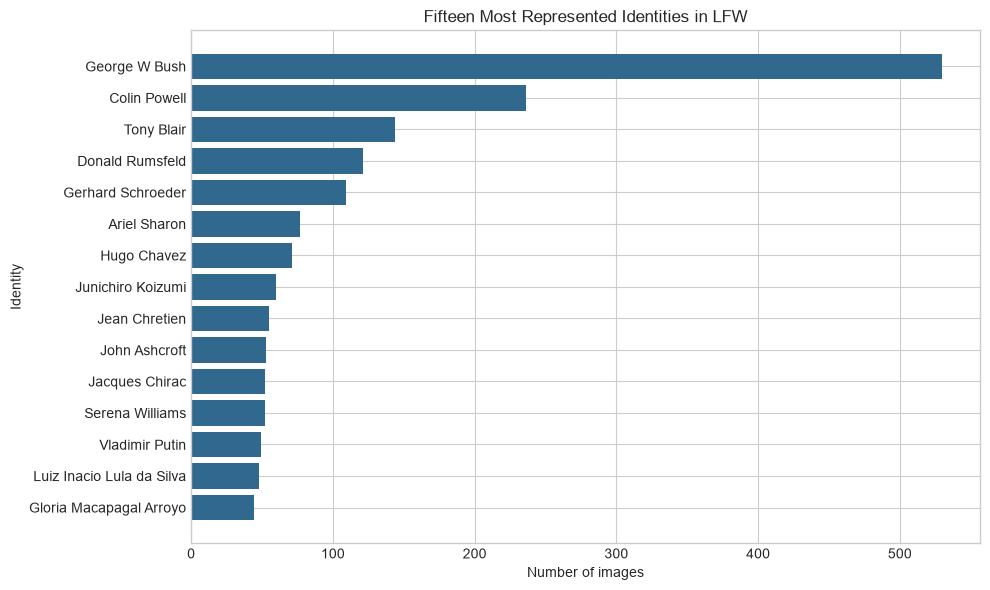

In [5]:
top_identities = identity_counts.head(15).sort_values("image_count")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_identities["identity"], top_identities["image_count"], color="#31688e")
ax.set_title("Fifteen Most Represented Identities in LFW")
ax.set_xlabel("Number of images")
ax.set_ylabel("Identity")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "lfw_identity_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

### Representative face images

One deterministic sample is displayed for each of the ten most represented identities. These examples provide an initial view of the variation in pose, expression, background, and illumination.

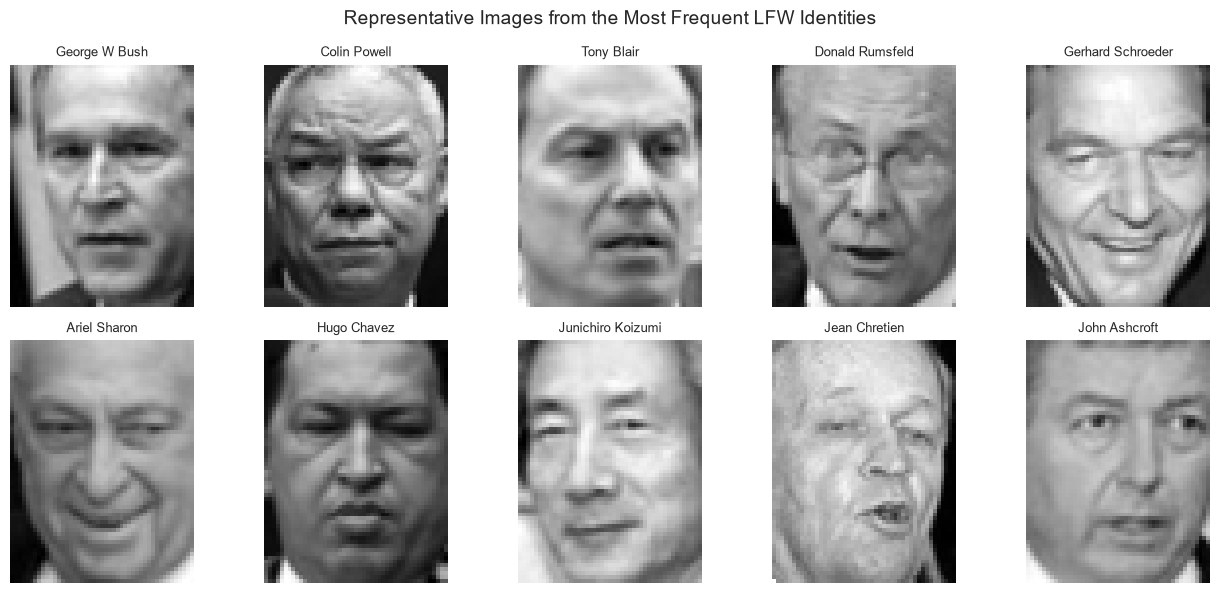

In [6]:
top_ten = identity_counts.head(10)
sample_indices = [np.flatnonzero(labels == identity_id)[0] for identity_id in top_ten["identity_id"]]

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for ax, sample_index in zip(axes.ravel(), sample_indices):
    ax.imshow(images[sample_index], cmap="gray")
    ax.set_title(identity_names[labels[sample_index]], fontsize=9)
    ax.axis("off")

fig.suptitle("Representative Images from the Most Frequent LFW Identities", fontsize=14)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "lfw_sample_faces.png", dpi=200, bbox_inches="tight")
plt.show()

### Exploration checkpoint

The next stage will use these counts to select five sufficiently represented identities and construct a balanced subset. No training, test splitting, PCA fitting, or classification is performed in this section.

## 2. Balanced five-identity subset

The complete LFW dataset is highly imbalanced. To create a controlled identification experiment, the five identities with the largest numbers of images are selected and exactly 50 images are sampled from each person.

Selection and sampling are deterministic because they use the fixed project random seed. The remaining images are not used in the experiment.

In [ ]:
N_IDENTITIES = 5
IMAGES_PER_IDENTITY = 50

eligible_identities = identity_counts.query("image_count >= @IMAGES_PER_IDENTITY")
selected_identity_rows = eligible_identities.head(N_IDENTITIES).copy()
selected_identity_rows["balanced_count"] = IMAGES_PER_IDENTITY

if len(selected_identity_rows) != N_IDENTITIES:
    raise ValueError("Not enough identities have the required number of images.")

display(
    selected_identity_rows[["identity_id", "identity", "image_count", "balanced_count"]]
    .rename(columns={"image_count": "available_count"})
)

### Reproducible balanced sampling

Each selected person is assigned a new class label from 0 to 4. Fifty source images are sampled without replacement for each class, combined, and shuffled. The original LFW indexes are retained so that the selection can be audited.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
selected_names = selected_identity_rows["identity"].to_numpy()

balanced_image_parts = []
balanced_feature_parts = []
balanced_label_parts = []
balanced_source_index_parts = []

for new_label, identity_id in enumerate(selected_identity_rows["identity_id"]):
    source_indices = np.flatnonzero(labels == identity_id)
    chosen_indices = rng.choice(
        source_indices, size=IMAGES_PER_IDENTITY, replace=False
    )

    balanced_image_parts.append(images[chosen_indices])
    balanced_feature_parts.append(features[chosen_indices])
    balanced_label_parts.append(np.full(IMAGES_PER_IDENTITY, new_label, dtype=int))
    balanced_source_index_parts.append(chosen_indices)

balanced_images = np.concatenate(balanced_image_parts)
balanced_features = np.concatenate(balanced_feature_parts)
balanced_labels = np.concatenate(balanced_label_parts)
balanced_source_indices = np.concatenate(balanced_source_index_parts)

shuffle_order = rng.permutation(len(balanced_labels))
balanced_images = balanced_images[shuffle_order]
balanced_features = balanced_features[shuffle_order]
balanced_labels = balanced_labels[shuffle_order]
balanced_source_indices = balanced_source_indices[shuffle_order]

### Integrity checks

The assertions below prevent the experiment from continuing if the subset has the wrong size, duplicate source images, inconsistent arrays, or unequal class counts.

In [ ]:
expected_total = N_IDENTITIES * IMAGES_PER_IDENTITY
balanced_counts = np.bincount(balanced_labels, minlength=N_IDENTITIES)

assert balanced_images.shape[0] == expected_total
assert balanced_features.shape[0] == expected_total
assert balanced_labels.shape[0] == expected_total
assert balanced_source_indices.shape[0] == expected_total
assert len(np.unique(balanced_source_indices)) == expected_total
assert np.all(balanced_counts == IMAGES_PER_IDENTITY)

balanced_summary = pd.DataFrame(
    {
        "class_label": np.arange(N_IDENTITIES),
        "identity": selected_names,
        "image_count": balanced_counts,
    }
)

display(balanced_summary)
print(f"Balanced image array: {balanced_images.shape}")
print(f"Balanced feature matrix: {balanced_features.shape}")
print(f"Unique source images: {len(np.unique(balanced_source_indices))}")

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(balanced_summary["identity"], balanced_summary["image_count"], color="#2a9d8f")
ax.bar_label(bars, padding=3)
ax.set_title("Balanced Five-Identity Dataset")
ax.set_xlabel("Identity")
ax.set_ylabel("Number of images")
ax.set_ylim(0, IMAGES_PER_IDENTITY + 10)
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "balanced_identity_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
SAMPLES_PER_IDENTITY = 5
fig, axes = plt.subplots(N_IDENTITIES, SAMPLES_PER_IDENTITY, figsize=(12, 11))

for class_label, identity_name in enumerate(selected_names):
    class_indices = np.flatnonzero(balanced_labels == class_label)[:SAMPLES_PER_IDENTITY]
    for column, sample_index in enumerate(class_indices):
        ax = axes[class_label, column]
        ax.imshow(balanced_images[sample_index], cmap="gray")
        ax.axis("off")
        if column == 0:
            ax.set_title(identity_name, loc="left", fontsize=10)

fig.suptitle("Five Samples per Selected Identity", fontsize=14)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "balanced_sample_faces.png", dpi=200, bbox_inches="tight")
plt.show()

### Balanced-subset checkpoint

The working dataset now contains 250 unique images: 50 images for each of five identities. The next stage creates a stratified train-test split while preserving equal representation.

## 3. Stratified train-test split

The balanced dataset is divided into 80% training data and 20% testing data. Stratification preserves the same number of images from every identity in both sets. The test set is held aside and will not be used to fit PCA or select k-NN parameters.

In [ ]:
TEST_SIZE = 0.20
all_indices = np.arange(len(balanced_labels))

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=balanced_labels,
)

X_train = balanced_features[train_indices]
X_test = balanced_features[test_indices]
y_train = balanced_labels[train_indices]
y_test = balanced_labels[test_indices]

train_images = balanced_images[train_indices]
test_images = balanced_images[test_indices]
train_source_indices = balanced_source_indices[train_indices]
test_source_indices = balanced_source_indices[test_indices]

### Split integrity checks

These checks verify the expected sizes, equal per-class representation, complete coverage of the balanced subset, and zero overlap between training and testing source images.

In [ ]:
expected_test_count = int(expected_total * TEST_SIZE)
expected_train_count = expected_total - expected_test_count
expected_test_per_identity = int(IMAGES_PER_IDENTITY * TEST_SIZE)
expected_train_per_identity = IMAGES_PER_IDENTITY - expected_test_per_identity

train_counts = np.bincount(y_train, minlength=N_IDENTITIES)
test_counts = np.bincount(y_test, minlength=N_IDENTITIES)

assert X_train.shape == (expected_train_count, balanced_features.shape[1])
assert X_test.shape == (expected_test_count, balanced_features.shape[1])
assert train_images.shape[0] == expected_train_count
assert test_images.shape[0] == expected_test_count
assert np.all(train_counts == expected_train_per_identity)
assert np.all(test_counts == expected_test_per_identity)
assert set(train_source_indices).isdisjoint(set(test_source_indices))
assert set(train_source_indices) | set(test_source_indices) == set(balanced_source_indices)

split_summary = pd.DataFrame(
    {
        "identity": selected_names,
        "training_images": train_counts,
        "testing_images": test_counts,
        "total_images": train_counts + test_counts,
    }
)

display(split_summary)
print(f"Training feature matrix: {X_train.shape}")
print(f"Testing feature matrix: {X_test.shape}")
print("Training/testing source overlap: 0 images")

In [ ]:
x_positions = np.arange(N_IDENTITIES)
bar_width = 0.38
fig, ax = plt.subplots(figsize=(10, 5.5))

training_bars = ax.bar(
    x_positions - bar_width / 2,
    train_counts,
    width=bar_width,
    label="Training",
    color="#2a9d8f",
)
testing_bars = ax.bar(
    x_positions + bar_width / 2,
    test_counts,
    width=bar_width,
    label="Testing",
    color="#e9c46a",
)

ax.bar_label(training_bars, padding=3)
ax.bar_label(testing_bars, padding=3)
ax.set_title("Stratified 80:20 Train-Test Split")
ax.set_xlabel("Identity")
ax.set_ylabel("Number of images")
ax.set_xticks(x_positions, selected_names, rotation=20)
ax.set_ylim(0, expected_train_per_identity + 8)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "train_test_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

### Train-test split checkpoint

The training set contains 200 images (40 per identity), and the held-out test set contains 50 images (10 per identity). All feature fitting and parameter selection in the next stages must use the training set only to prevent test-data leakage.